In [2]:
import cv2
import numpy as np
import os
import glob

def add_fog(image, intensity=0.4):
    overlay = np.full_like(image, 255, dtype=np.uint8)
    return cv2.addWeighted(image, 1 - intensity, overlay, intensity, 0)

def add_rain(image, drop_count=400):
    rain_layer = np.zeros_like(image, dtype=np.uint8)
    h, w = image.shape[:2]
    for _ in range(drop_count):
        x = np.random.randint(0, w)
        y = np.random.randint(0, h)
        length = np.random.randint(10, 20)
        angle = np.random.randint(-3, 3)
        cv2.line(rain_layer, (x, y), (x + angle, y + length), (200, 200, 200), 1)
    rain_layer = cv2.GaussianBlur(rain_layer, (3, 3), 0)
    return cv2.add(image, rain_layer)

# 设置输入和输出文件夹
input_dir = r"E:\Download\BaiduNetdiskDownload\CCPD2020\ccpd_green\rain"
output_dir = r"E:\Download\BaiduNetdiskDownload\CCPD2020\ccpd_green\rain_generated"

if not os.path.exists(output_dir):
    os.makedirs(output_dir)

# 获取所有图片路径
image_paths = glob.glob(os.path.join(input_dir, "*.jpg")) + glob.glob(os.path.join(input_dir, "*.png"))

for img_path in image_paths:
    filename = os.path.basename(img_path)
    img = cv2.imread(img_path)
    
    if img is not None:
        # 默认生成下雨效果。如果需要起雾效果，可替换为: result_img = add_fog(img)
        result_img = add_rain(img, drop_count=500)
        
        save_path = os.path.join(output_dir, filename)
        cv2.imwrite(save_path, result_img)

✅ 成功导入模型定义！


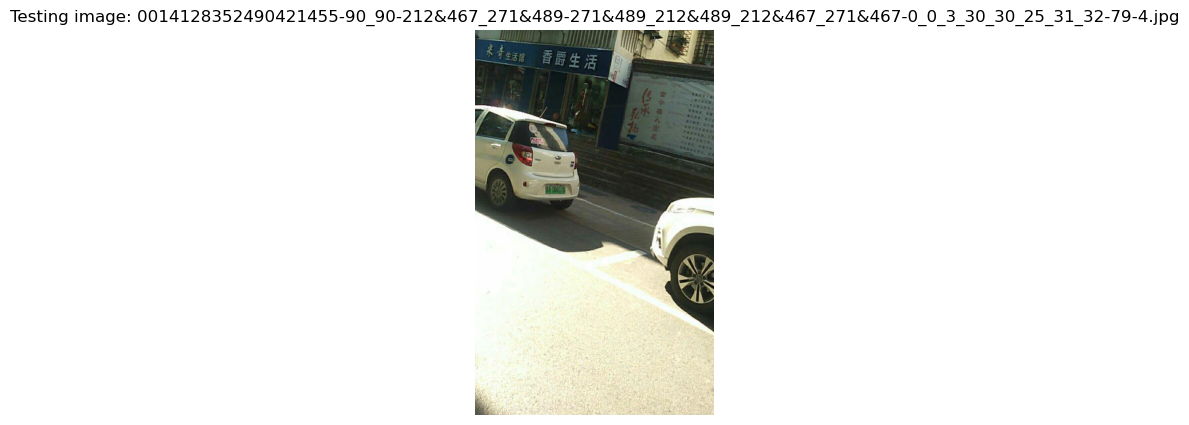

下一步：我们需要编写具体的推理逻辑来让模型‘说话’。


In [21]:
import os
import sys
import torch
import cv2
import numpy as np
from matplotlib import pyplot as plt

# 1. 关键步骤：手动把项目根目录添加到系统路径
# 请确保这个路径是你项目的根目录
project_root = r'E:\Download\BaiduNetdiskDownload\LPRNet_Pytorch-master'
if project_root not in sys.path:
    sys.path.append(project_root)

# 现在尝试导入（如果你的文件夹叫 model，里面有 LPRNet.py）
try:
    from model.LPRNet import LPRNet
    print("✅ 成功导入模型定义！")
except ModuleNotFoundError:
    print("❌ 还是找不到 model 文件夹，请确认该文件夹就在项目根目录下。")

# 2. 设置测试路径
#test_folder = r'E:\Download\BaiduNetdiskDownload\CCPD2020\ccpd_green\rain_generated'
test_folder = r'E:\Download\BaiduNetdiskDownload\CCPD2020\ccpd_green\test'

weights_path = os.path.join(project_root, 'weights/Final_LPRNet_model.pth') # 确认权重文件名对不对

# 3. 简单看一张图的效果（可视化）
img_list = os.listdir(test_folder)
if len(img_list) > 0:
    sample_path = os.path.join(test_folder, img_list[0])
    img = cv2.imread(sample_path)
    
    # 在 Jupyter 里显示这张“下雨”的车牌
    plt.figure(figsize=(10, 5))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(f"Testing image: {img_list[0]}")
    plt.axis('off')
    plt.show()

print("下一步：我们需要编写具体的推理逻辑来让模型‘说话’。")

In [35]:
import os

# 1. 定义数据路径
train_root = r'E:\Download\BaiduNetdiskDownload\CCPD2020\ccpd_green\train' # 原始绿牌
val_root = r'E:\Download\BaiduNetdiskDownload\CCPD2020\ccpd_green\val'     # 验证集
rain_root = r'E:\Download\BaiduNetdiskDownload\CCPD2020\ccpd_green\rain_generated' # 你生成的雨天图

# 💡 建议：把一部分雨天图也放进 train 路径，模型才能学会识别雨天！
print(f"训练集图片数量: {len(os.listdir(train_root))}")

训练集图片数量: 5769


In [42]:
# 这是一个简化的启动逻辑
from train_LPRNet import train # 假设 train_LPRNet.py 里有 train 函数

# 设置训练参数
args = {
    'train_img_dirs': train_root,
    'test_img_dirs': val_root,
    'dropout_rate': 0.5,
    'learning_rate': 0.1,
    'gpu_id': '0',
    'checkpoints': 'weights'
}

# 建议在 VS Code 终端跑这行，Jupyter 容易崩：
# !python train_LPRNet.py --train_img_dirs E:\...\train --max_epoch 50

In [ ]:
# 1. 确保你在项目根目录下
import os
os.chdir(r'E:\Download\BaiduNetdiskDownload\LPRNet_Pytorch-master')

# 2. 定义训练参数
# --train_img_dirs: 填你存放混合了雨天和正常图片的文件夹
# --test_img_dirs: 填验证集文件夹
# --max_epoch: 先设为 50 试试
# --train_batch_size: 如果显存报错(Out of Memory)，就把 64 改成 32 或 16

!python train_LPRNet.py \
    --train_img_dirs "E:\Download\BaiduNetdiskDownload\CCPD2020\ccpd_green\train" \
    --test_img_dirs "E:\Download\BaiduNetdiskDownload\CCPD2020\ccpd_green\val" \
    --max_epoch 50 \
    --train_batch_size 32